# Full interaction (Heisenberg + RKKY) and disorder (missing spins)

In [1]:
using Pkg; Pkg.update()
using Base.Filesystem: readdir
using OffsetArrays: OffsetArray, Origin
using HDF5

using MX2RKKY.visualization
using MX2RKKY.montecarlo: Configuration

include("T_scan_postprocessing.jl")

    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `/home/igor/Physics/MX2-RKKY/MX2RKKY.git`
   Installed JpegTurbo_jll ─────── v3.2.1+0
   Installed Missings ──────────── v1.2.1
   Installed Accessors ─────────── v0.1.46
   Installed Roots ─────────────── v3.0.13
   Installed JSON ──────────────── v1.13.4
   Installed RecursiveArrayTools ─ v4.5.6
   Installed AdaptiveArrayPools ── v0.3.12
   Installed LinearSolve ───────── v5.18.3
   Installed FriBidi_jll ───────── v1.0.19+0
   Installed MicrosoftMPI_jll ──── v10.1.5+0
   Installed SentinelArrays ────── v1.4.11
   Installed SciMLOperators ────── v1.30.4
   Installed ColorTypes ────────── v0.12.5
   Installed Setfield ──────────── v1.2.0
   Installed ColorVectorSpace ──── v0.11.2
   Installed Parsers ───────────── v3.0.5
   Installed NonlinearSolveBase ── v2.55.1
   Installed CSV ───────────────── v1.3.0
   Installed Colors ────────────── v0.13.4
   Installed ChainRulesCore ────── v1.26.8
   Installed lib

export_observables

## Plots

regex = r"RKKY_T_scan_V0.0001_lambda0.1_R0_L15_init_chi1_nvac[0-9]+_dseed[0-9]+.h5"


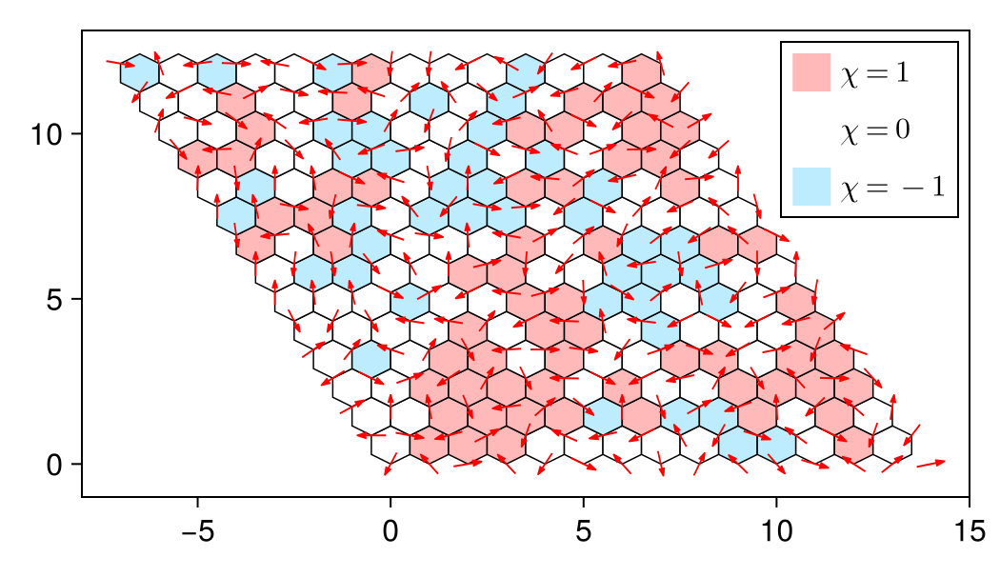

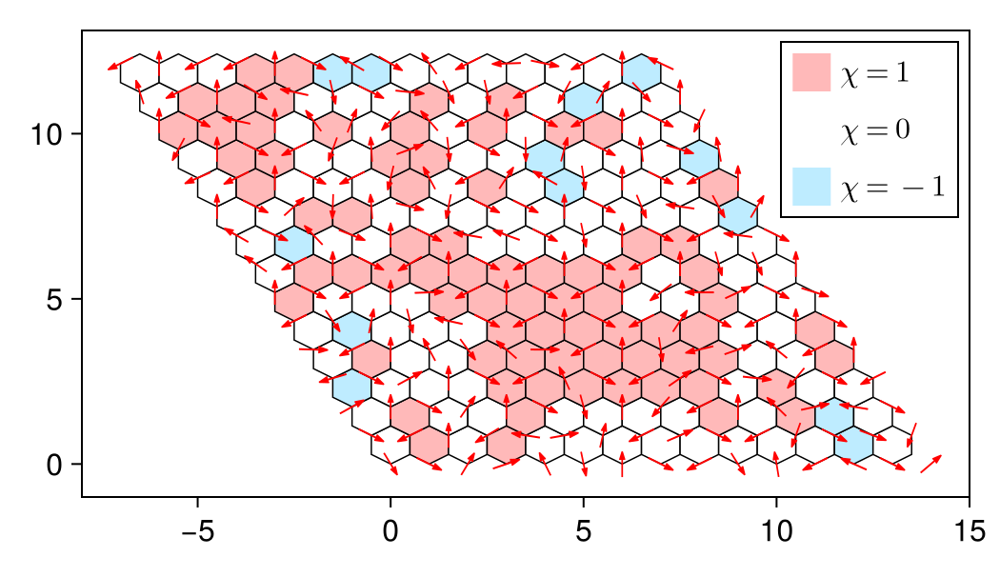

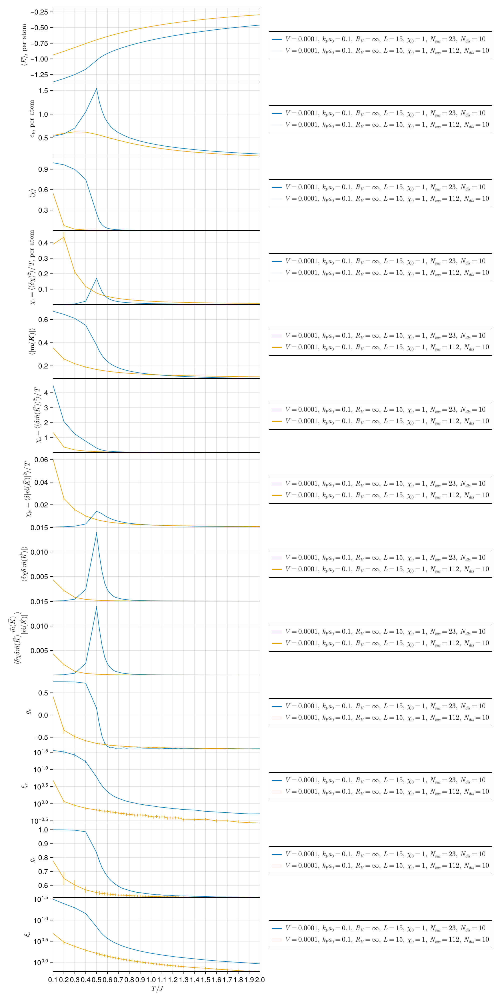

In [10]:
V = 0.0001
L = 15
regex = Regex("RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_init_chi1_nvac[0-9]+_dseed[0-9]+.h5")

dfs = DataFrame[]
for name in ["2026.10.17", "2026.10.20"]
    ars = [h5open(filename, "r") for filename in readdir("../../RKKY_temperature_scan_disorder/$(name)", join=true)
           if !isnothing(match(regex, filename))
    ]

    # Plot final configuration at T=0.5
    conf = Configuration(OffsetArray(ars[1]["T0.5/final_conf"][], Origin(0)))
    display(plot_conf(conf))
    
    df = make_disorder_averaged_df(ars);
    export_observables(df)
    push!(dfs, df)
end
plot_observables(dfs, pdfname="RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_nvac23,112_ndis10.pdf")

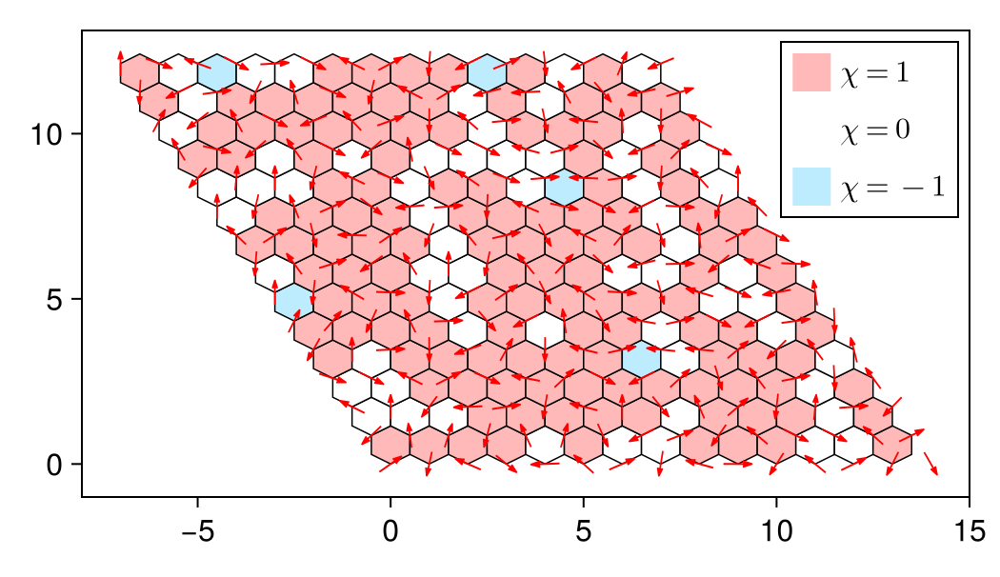

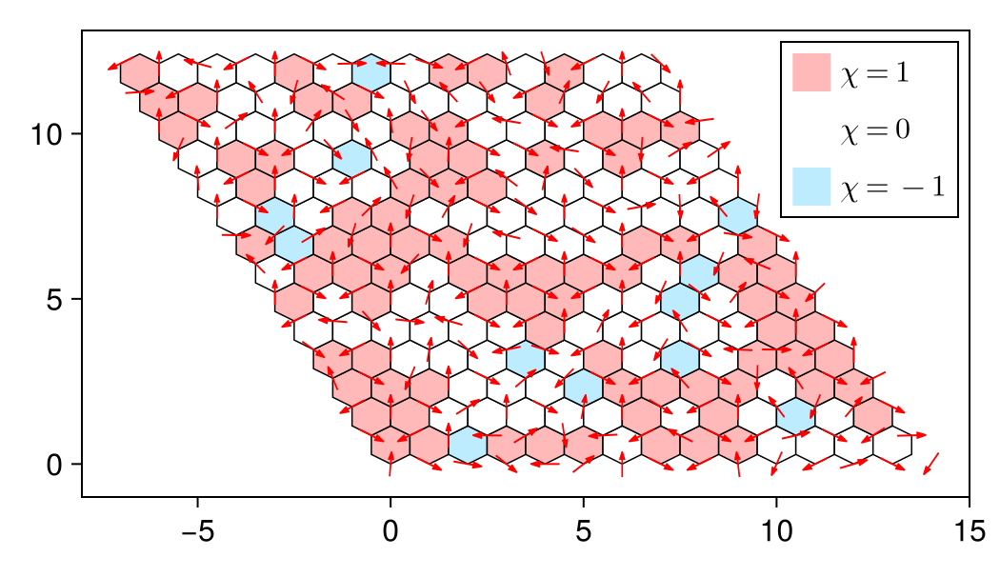

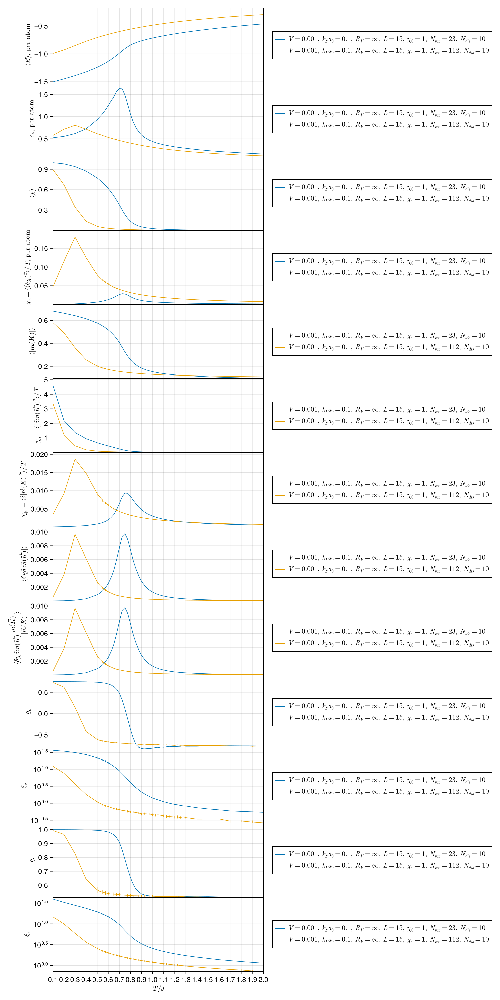

In [11]:
V = 0.001
L = 15

dfs = DataFrame[]
name = "2026.10.21"
for nvac in [23, 112]
    regex = Regex("RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_init_chi1_nvac$(nvac)_dseed[0-9]+.h5")
    ars = [h5open(filename, "r") for filename in readdir("../../RKKY_temperature_scan_disorder/$(name)", join=true)
        if !isnothing(match(regex, filename))
    ]

    # Plot final configuration at T=0.5
    conf = Configuration(OffsetArray(ars[1]["T0.5/final_conf"][], Origin(0)))
    display(plot_conf(conf))
    
    df = make_disorder_averaged_df(ars);
    export_observables(df)
    push!(dfs, df)
end
plot_observables(dfs, pdfname="RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_nvac23,112_ndis10.pdf")

## $N_\text{dis} = 100$

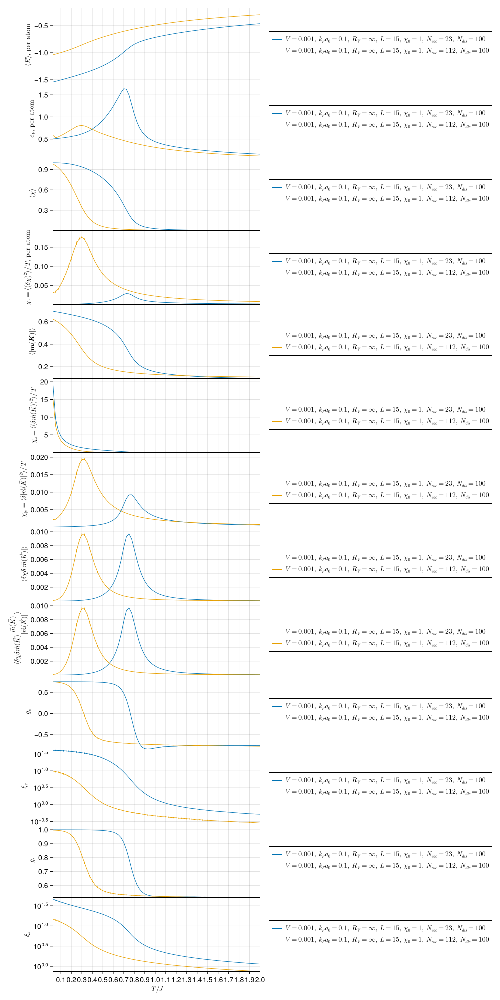

In [7]:
V = 0.001
L = 15

dfs = DataFrame[]
for (name, nvac) in [("2026.10.25", 23), ("2026.10.26", 112)]
    regex = Regex("RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_init_chi1_nvac$(nvac)_dseed[0-9]+.h5")
    ars = [h5open(filename, "r") for filename in readdir("../../RKKY_temperature_scan_disorder/$(name)", join=true)
        if !isnothing(match(regex, filename))
    ]
    
    df = make_disorder_averaged_df(ars);
    export_observables(df)
    push!(dfs, df)
end
plot_observables(dfs, pdfname="RKKY_T_scan_V$(V)_lambda0.1_R0_L$(L)_nvac23,112_ndis100.pdf")

## $V=0$

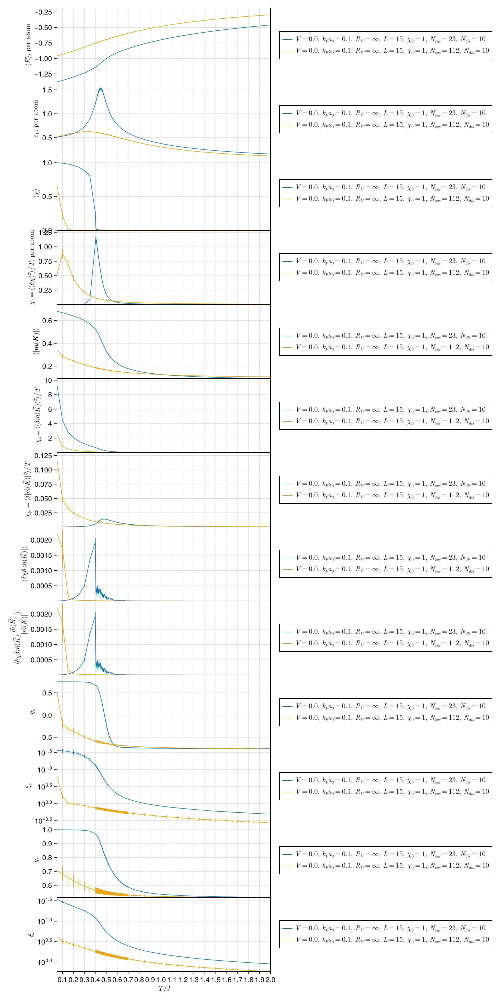

In [2]:
L = 15

dfs = DataFrame[]
for (name, nvac) in [("2026.10.28", 23), ("2026.10.30", 112)]
    regex = Regex("XY_T_scan_L$(L)_init_chi1_nvac$(nvac)_dseed[0-9]+.h5")
    ars = [h5open(filename, "r") for filename in readdir("../../RKKY_temperature_scan_disorder/$(name)", join=true)
        if !isnothing(match(regex, filename))
    ]
    
    df = make_disorder_averaged_df(ars);
    export_observables(df)
    push!(dfs, df)
end
plot_observables(dfs, pdfname="XY_T_scan_L$(L)_nvac23,112_ndis10.pdf")